### РОССИЙСКИЙ УНИВЕРСИТЕТ ДРУЖБЫ НАРОДОВ

#### Факультет физико-математических и естественных наук

## ОТЧЁТ ПО КОНТРОЛЬНОЙ ТОЧКЕ №3 (КТ 3)

### Научно-исследовательская практика (магистратура, 2-й курс)

### Моделирование движения колёсного мобильного робота по заданным точкам траектории

### Базовая модель Baseline v1: вывод уравнений, численное интегрирование, валидация и формирование целевых состояний

##### Студент: Акондзо Жордани Лади Гаэл

## Москва 2026

***

## Задание КТ 3. Базовая модель, численное интегрирование и целевые состояния

Мы рассматриваем плоское твёрдое тело с идеальной неголономной связью «отсутствие бокового скольжения» (модель **Baseline v1**). Эта модель носит предварительный характер: мы принимаем её как первое приближение. Она не описывает конкретную конструкцию колёсного привода и не учитывает схему рулевого управления Аккермана.

В работе нам необходимо:

1. Зафиксировать допущения и вывести уравнения движения.
2. Проверить вывод символьно (SymPy) независимо от кода из `src/`.
3. Выполнить численное интегрирование трёх сценариев и сопоставить результаты с независимыми эталонами.
4. Проанализировать невязку неголономной связи и её дрейф.
5. Сформировать целевые состояния $T_i = X(t_i)$ и проверить воспроизводимость их записи и чтения.
6. Сформулировать ограничения модели и полученных результатов.

Все параметры, начальные условия и целевые состояния в работе синтетические: они получены численным моделированием и не являются измерениями физического робота.

## Решение

### 1. Цель работы

Целью работы является построение и проверка воспроизводимой вычислительной цепочки «уравнения движения, численная траектория, целевые состояния» для базовой динамической модели неголономного колёсного робота. Мы оцениваем, насколько численное решение сохраняет неголономную связь и согласуется с независимыми аналитическими и численными эталонами, а также фиксируем границы применимости модели.

### 2. Теоретические сведения

**Неголономная связь.** Связь вида $A(q)\,\dot q = 0$ мы называем неголономной, если её нельзя свести к ограничению на координаты $q$ (она не интегрируется). Системы с неинтегрируемыми ограничениями на скорости относятся к классу неголономных механических систем [1]. Для тела на плоскости, у которого скорость опорной точки направлена вдоль продольной оси, мы имеем $q=(x,y,\theta)^T$ и
$$A(q)=\begin{bmatrix}\sin\theta & -\cos\theta & 0\end{bmatrix},\qquad r(X)=\dot x\sin\theta-\dot y\cos\theta=0 .$$
Величина $r$ (м/с) равна поперечной скорости в связанной системе координат, взятой с обратным знаком. Мы называем её **невязкой связи**. Ограничения такого типа характерны для ряда колёсных мобильных роботов, движение которых допускает продольное перемещение, но исключает мгновенное боковое скольжение [2].

**Уравнения Лагранжа-Даламбера.** Для системы с матрицей инерции $M$, обобщёнными силами $B u$ и связью $A\dot q=0$ динамика описывается уравнением
$$M\ddot q = B u + A^{T}\lambda,$$
где $\lambda$ является скалярным множителем Лагранжа, соответствующим связи, а $Q_c=A^{T}\lambda$ является обобщённой силой реакции связи. Принцип Лагранжа-Даламбера для систем с неголономными связями изложен в [1]. Мы находим $\lambda$ из условия $\dot r = 0$.

**Численное решение.** Мы записываем модель как задачу Коши $\dot X = f(t,X)$, $X(t_0)=X_0$, и решаем её адаптивными явными методами Рунге-Кутты [3]: `RK45` (пара Дормана-Принса порядка 5(4)) и `DOP853` (порядок 8(5,3)). Шаг выбирается так, чтобы оценка локальной ошибки $e_i$ удовлетворяла условию $|e_i|\lesssim \mathrm{atol}+\mathrm{rtol}\,|X_i|$ [3]. Методы с вложенными формулами Рунге-Кутты, включая семейство Dormand-Prince, широко используются для адаптивного выбора шага интегрирования [3, 4]. Метод `DOP853` относится к семейству явных методов Рунге-Кутты высокого порядка, применяемых для нежёстких задач [3]. Параметры `rtol` и `atol` мы задаём явно.

**Дрейф невязки.** Интегратор не контролирует связь $r=0$ напрямую. Если $r$ является первым интегралом точного потока, то величина $|r(t)-r(0)|$ вдоль численного решения измеряет именно **ошибку интегрирования**, а не ошибку модели.

Источники [1, 2] мы приводим только для общих сведений о неголономных системах, а источники [3, 4] только для общих сведений о численных методах. Конкретная модель Baseline v1 является нашим предварительным построением и в этих источниках не приводится.

**Целевые состояния.** Целевым состоянием мы называем значение полного вектора состояния в выбранный момент времени, $T_i = X(t_i)$.

### 3. Постановка задачи

**Дано:** параметры $m,\,J$; программные (разомкнутые) управления $F(t),\,\tau(t)$; начальное состояние $X_0$, удовлетворяющее условию $r(X_0)=0$; моменты времени $t_i$.

**Требуется:** найти $X(t)$ на отрезке $[0,t_f]$, оценить дрейф невязки $|r(t)-r(0)|$ и сформировать набор целевых состояний $T_i=X(t_i)$.

Обозначения и единицы измерения приведены в таблице.

| Обозначение | Смысл | Единицы |
|---|---|---|
| $x,\ y$ | координаты опорной точки (центра масс) | м |
| $\theta$ | угол курса | рад |
| $\dot x,\ \dot y$ | проекции скорости на оси неподвижной системы | м/с |
| $\omega=\dot\theta$ | угловая скорость | рад/с |
| $v=\dot x\cos\theta+\dot y\sin\theta$ | скорость вдоль продольной оси | м/с |
| $F$ | продольная сила вдоль оси корпуса | Н |
| $\tau$ | момент рыскания | Н·м |
| $m$ | масса | кг |
| $J$ | момент инерции относительно вертикальной оси | кг·м² |
| $r$ | невязка связи | м/с |

Вектор состояния $X=(x,y,\theta,\dot x,\dot y,\dot\theta)^T\in\mathbb R^{6}$ имеет размерность 6, вектор управления $u=(F,\tau)$ имеет размерность 2.

### 4. Математическая модель

**Допущения.** Мы принимаем следующие допущения: движение происходит в горизонтальной плоскости; тело абсолютно твёрдое; опорная точка совпадает с центром масс; связь $r=0$ идеальна; динамика приводов колёс и рулевого механизма не рассматривается; диссипация отсутствует; управления являются заданными функциями времени.

**Вывод.** Кинетическая энергия тела
$$T=\frac12\,m(\dot x^2+\dot y^2)+\frac12\,J\dot\theta^2=\frac12\,\dot q^{T}M\dot q$$
(далее мы обозначаем её $E$, чтобы не путать с целевыми состояниями $T_i$) приводит к инерционным членам $M\ddot q$ с матрицей $M=\mathrm{diag}(m,m,J)$. Мы исходим из уравнения Лагранжа-Даламбера при $Bu=(F\cos\theta,\ F\sin\theta,\ \tau)^T$:
$$m\ddot x=F\cos\theta+\lambda\sin\theta,\qquad m\ddot y=F\sin\theta-\lambda\cos\theta,\qquad J\ddot\theta=\tau .$$
Здесь $\lambda$ является скалярным множителем Лагранжа, соответствующим связи, а обобщённая сила реакции равна $Q_c=A^{T}\lambda=(\lambda\sin\theta,\,-\lambda\cos\theta,\,0)^T$.
Продифференцируем невязку вдоль движения:
$$\dot r=\ddot x\sin\theta-\ddot y\cos\theta+\dot\theta\,(\dot x\cos\theta+\dot y\sin\theta)=\frac{\lambda}{m}+\omega v .$$
Слагаемые с $F$ при этом взаимно уничтожаются, а $\sin^2\theta+\cos^2\theta=1$. Из условия $\dot r=0$ мы получаем
$$\boxed{\lambda=-m\,v\,\omega}.$$
Подстановка в уравнения движения даёт векторное поле, реализованное в `src.model.rhs`:
$$\ddot x=\frac{F}{m}\cos\theta-v\,\omega\sin\theta,\qquad \ddot y=\frac{F}{m}\sin\theta+v\,\omega\cos\theta,\qquad \ddot\theta=\frac{\tau}{J}.$$

**Следствия.** Мы проверяем их символьно в разделе 6 и в тестах из `tests/`.

1. Производная $\dot r$ равна нулю **при любом** состоянии, а не только на множестве $r=0$. Следовательно, $r$ является первым интегралом: начальное нарушение связи не затухает и не нарастает, то есть поток связь не «исправляет».
2. Выполняется равенство $\dot v=\dfrac{F}{m}-\omega\,r$; на множестве $r=0$ оно принимает вид $\dot v=F/m$.
3. Для кинетической энергии $E=\tfrac12 m(\dot x^2+\dot y^2)+\tfrac12 J\omega^2$ и мощности $P=Fv+\tau\omega$ справедливо равенство $\dot E=P-m\,v\,\omega\,r$; на множестве $r=0$ получаем баланс $\dot E=P$.

**Редуцированная форма (только для проверки).** Мы вводим состояние $Z=(x,y,\theta,v,\omega)^T\in\mathbb R^5$, для которого
$$\dot Z=\bigl(v\cos\theta,\ v\sin\theta,\ \omega,\ F/m,\ \tau/J\bigr)^T,\qquad X=R(Z)=(x,y,\theta,v\cos\theta,v\sin\theta,\omega)^T .$$
Эта форма эквивалентна полной модели только при $r=0$. Мы используем её как независимую перекрёстную проверку, а не как вторую модель.

### 5. Подготовка вычислительной среды

Устойчивая научная логика находится в модулях `src/`, а в ноутбуке мы только вызываем её и интерпретируем результаты. Общие параметры эксперимента (`PARAMS`, `SOLVER`, `T`, `T_TARGETS`, `SCENARIOS`) мы берём из `experiments/run_kt3.py`, чтобы ноутбук и экспериментальный скрипт использовали одни и те же значения.

In [1]:
import os, sys, platform, tempfile, pathlib
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import sympy as sp
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import quad

from src.model import (Params, constant_control, rhs, rhs_reduced, reconstruct, reduce_state,
                       body_speed, free_motion_exact)
from src.solver import integrate
from src.metrics import (constraint_residual, residual_drift, position_error,
                         kinetic_energy, energy_balance_error)
from src.dataset import sample_targets, save_targets, load_targets
from experiments.run_kt3 import PARAMS, SOLVER, T, T_TARGETS, SCENARIOS, run_scenario

%matplotlib inline

print("Python", platform.python_version(), "| NumPy", np.__version__, "| SciPy", scipy.__version__,
      "| SymPy", sp.__version__, "| Matplotlib", matplotlib.__version__)
print("Параметры:", PARAMS, "| решатель:", SOLVER)
print("Сетка времени: шаг %.2f с, [0, %.0f] с, %d узлов; моменты t_i:" % (T[1] - T[0], T[-1], T.size), T_TARGETS)

Python 3.13.9 | NumPy 2.5.4 | SciPy 1.18.1 | SymPy 1.14.0 | Matplotlib 3.11.2
Параметры: Params(m=10.0, J=2.0) | решатель: {'method': 'DOP853', 'rtol': 1e-10, 'atol': 1e-12}
Сетка времени: шаг 0.05 с, [0, 10] с, 201 узлов; моменты t_i: [ 2.  4.  6.  8. 10.]


**Интерпретация.** Параметры $m=10$ кг и $J=2$ кг·м², решатель `DOP853` с `rtol=1e-10` и `atol=1e-12`, шаг сетки 0,05 с и пять моментов $t_i=2,4,6,8,10$ с являются **синтетическими допущениями эксперимента**. Они не получены из измерений и не заданы научным руководителем.

### 6. Символьная проверка модели

Мы выполняем проверку в SymPy, исходя из уравнений Лагранжа-Даламбера, и **не используем** при этом код из `src/`. Сначала мы находим множитель $\lambda$ из условия $\dot r=0$, затем проверяем тождества из раздела 4.

In [2]:
m_, J_, F_, tau_, lam = sp.symbols("m J F tau lambda", real=True)
th, vx, vy, w = sp.symbols("theta v_x v_y omega", real=True)
v_ = vx*sp.cos(th) + vy*sp.sin(th)
r_ = vx*sp.sin(th) - vy*sp.cos(th)
ax = (F_*sp.cos(th) + lam*sp.sin(th)) / m_
ay = (F_*sp.sin(th) - lam*sp.cos(th)) / m_
rdot = lambda ax, ay: ax*sp.sin(th) + w*vx*sp.cos(th) - ay*sp.cos(th) + w*vy*sp.sin(th)

(lam_sol,) = sp.solve(sp.Eq(sp.simplify(rdot(ax, ay)), 0), lam)
print("lambda            =", sp.simplify(lam_sol))
print("lambda + m v omega =", sp.simplify(lam_sol + m_*v_*w))

ax_s, ay_s = ax.subs(lam, lam_sol), ay.subs(lam, lam_sol)
vdot = ax_s*sp.cos(th) + ay_s*sp.sin(th) + w*(-vx*sp.sin(th) + vy*sp.cos(th))
Edot = m_*(vx*ax_s + vy*ay_s) + J_*w*tau_/J_
print("rdot              =", sp.simplify(rdot(ax_s, ay_s)))
print("vdot - (F/m - w r) =", sp.simplify(vdot - (F_/m_ - w*r_)))
print("Edot - (P - m v w r) =", sp.simplify(Edot - (F_*v_ + tau_*w - m_*v_*w*r_)))

lambda            = -m*omega*(v_x*cos(theta) + v_y*sin(theta))
lambda + m v omega = 0
rdot              = 0
vdot - (F/m - w r) = 0
Edot - (P - m v w r) = 0


**Интерпретация.** Мы получили $\lambda=-m\,v\,\omega$. Производная невязки $\dot r$ тождественно равна нулю при произвольных $(\theta,\dot x,\dot y)$, а тождества $\dot v=F/m-\omega r$ и $\dot E=P-m v\omega r$ выполняются. Тем самым вывод из раздела 4 подтверждён независимо от кода.

In [3]:
# Тот же вывод для реализованного поля src.model.rhs: случайные состояния, в том числе с r != 0.
rng = np.random.default_rng(20261024)
ctrl = constant_control(3.7, -1.1)
worst = 0.0
for X in rng.uniform(-3, 3, size=(300, 6)):
    f = rhs(0.0, X, PARAMS, ctrl)
    rdot_num = f[3]*np.sin(X[2]) - f[4]*np.cos(X[2]) + X[5]*body_speed(X)
    worst = max(worst, abs(rdot_num) / (1 + np.abs(X).max()**2))
print("max |r'| для 300 случайных состояний (с масштабированием): %.2e" % worst)

max |r'| для 300 случайных состояний (с масштабированием): 2.17e-16


**Интерпретация.** Реализация в коде удовлетворяет тождеству $\dot r=0$ с точностью порядка машинной, в том числе вне множества $r=0$. Следовательно, код согласован с символьным выводом.

### 7. Численное интегрирование

Мы используем обёртку `src.solver.integrate` над `scipy.integrate.solve_ivp`. Параметры `method`, `rtol` и `atol` являются обязательными именованными аргументами, поэтому скрытых значений по умолчанию нет. Слишком малое `rtol` (которое SciPy молча увеличило бы) и нечисловые значения отклоняются, а сбой решателя приводит к исключению.

**Выбор метода.** Правая часть гладкая и нежёсткая, поэтому мы применяем адаптивные явные методы Рунге-Кутты [3]. Для основных расчётов мы выбрали `DOP853` (метод высокого порядка для строгих допусков [3]). Это проектное решение, а не вывод из сравнения ниже. Методы `RK45` и неявный `Radau` мы используем как альтернативные решатели для оценки чувствительности.

**Чувствительность к допускам.** Сценарий S2 (окружность) имеет решение в замкнутом виде, поэтому ошибку интегрирования мы измеряем напрямую как $\max_{t,i}|X_i(t)-X_i^{\text{точн}}(t)|$.

In [4]:
name2, Z0_2, F2, tau2, closed2 = SCENARIOS[1]
X0_2, exact2, ctrl2 = reconstruct(np.array(Z0_2)), free_motion_exact(T, *closed2), constant_control(F2, tau2)
rows = []
for rtol in (1e-4, 1e-6, 1e-8, 1e-10, 1e-12):
    row = {"rtol": rtol}
    for method in ("RK45", "DOP853", "Radau"):
        X = integrate(rhs, X0_2, T, PARAMS, ctrl2, method=method, rtol=rtol, atol=1e-2*rtol)
        row[method] = np.abs(X - exact2).max()
    rows.append(row)
err_table = pd.DataFrame(rows).set_index("rtol")
err_table.index = [f"{r:.0e}" for r in err_table.index]
err_table.style.format("{:.2e}")

,RK45,DOP853,Radau
1e-04,7.61e-04,7.47e-04,4.27e-05
1e-06,3.82e-06,1.04e-05,3.57e-07
1e-08,1.65e-08,2.02e-07,3.46e-09
1e-10,8.39e-11,1.87e-09,3.08e-11
1e-12,5.27e-13,1.80e-11,4.72e-13


**Интерпретация.**

**Результат.** В этом эксперименте для всех трёх методов ошибка убывает при ужесточении `rtol`. От $\mathrm{rtol}=10^{-4}$ до $10^{-12}$ она уменьшается для `RK45` с $7{,}6\cdot10^{-4}$ до $5{,}3\cdot10^{-13}$, для `DOP853` с $7{,}5\cdot10^{-4}$ до $1{,}8\cdot10^{-11}$, для `Radau` с $4{,}3\cdot10^{-5}$ до $4{,}7\cdot10^{-13}$. Уровни ошибки и скорость её убывания у методов различаются: при $\mathrm{rtol}=10^{-10}$ ошибки `RK45`, `DOP853` и `Radau` равны $8{,}4\cdot10^{-11}$, $1{,}9\cdot10^{-9}$ и $3{,}1\cdot10^{-11}$ соответственно.

**Значение.** Параметр `rtol` управляет *локальной* ошибкой шага, а глобальная ошибка на отрезке интегрирования зависит ещё от метода и от задачи. Для принятых допусков ($\mathrm{rtol}=10^{-10}$, `DOP853`) ошибка на S2 имеет порядок $10^{-9}$; этот уровень задаёт масштаб численных диагностик ниже. Ошибку модели мы здесь не оцениваем.

**Ограничение.** Сравнение выполнено на одном сценарии (S2), при фиксированном соотношении $\mathrm{atol}=10^{-2}\,\mathrm{rtol}$ и без учёта стоимости методов. По этому эксперименту нельзя признать какой-либо метод лучшим в общем случае; выбор `DOP853` остаётся проектным решением.

### 8. Сценарии вычислительного эксперимента

Мы рассматриваем три сценария возрастающей сложности. Начальные состояния задаются через $Z_0=(x,y,\theta,v,\omega)$ и переводятся в $X_0=R(Z_0)$, поэтому $r(X_0)=0$.

| Сценарий | $Z_0=(x,y,\theta,v,\omega)$ | $F$, Н | $\tau$, Н·м | Независимый эталон |
|---|---|---|---|---|
| S1_line | $(0,\,0,\,0,\,1,\,0)$ | 0 | 0 | замкнутая форма: прямая |
| S2_arc | $(0,\,0,\,0,\,1{,}5,\,0{,}6)$ | 0 | 0 | замкнутая форма: окружность радиуса $v_0/\omega_0=2{,}5$ м |
| S3_const_F_tau | $(0,\,0,\,0,\,1,\,0{,}3)$ | 2 | 0,2 | аналитические $v(t),\omega(t),\theta(t)$ и квадратура для $x(t),y(t)$ |

**Сценарии S1 и S2** ($F=\tau=0$). Здесь $v\equiv v_0$ и $\omega\equiv\omega_0$, поэтому движение равномерное: по прямой при $\omega_0=0$ и по окружности радиуса $v_0/\omega_0$ при $\omega_0\ne0$.

**Сценарий S3** ($F$ и $\tau$ постоянны). Замкнутое решение для координат $x(t),y(t)$ мы **не используем**. Траекторию мы проверяем независимо: по аналитическим выражениям для $v(t)$, $\omega(t)$ и $\theta(t)$, а затем численной квадратурой для $x(t)$ и $y(t)$. На множестве $r=0$ выполняются равенства $\dot v=F/m$, $\dot\omega=\tau/J$, $\dot\theta=\omega$, откуда
$$v(t)=v_0+\frac{F}{m}\,t,\qquad \omega(t)=\omega_0+\frac{\tau}{J}\,t,\qquad \theta(t)=\theta_0+\omega_0 t+\frac{\tau}{2J}\,t^2 .$$
Так как $\dot x=v\cos\theta$ и $\dot y=v\sin\theta$ при $r=0$, координаты выражаются интегралами
$$x(t)=x_0+\int_0^t v(s)\cos\theta(s)\,ds,\qquad y(t)=y_0+\int_0^t v(s)\sin\theta(s)\,ds .$$
Мы вычисляем их адаптивной квадратурой (`scipy.integrate.quad`) и сравниваем с численным решением в целевые моменты времени.

В сценарии S3 скорость $v(t)$ и угловая скорость $\omega(t)$ изменяются линейно, а кривизна $\omega/v$ непостоянна. Геометрическую классификацию этой кривой мы в работе не проводим.

In [5]:
sims = {}
for name, Z0, F, tau, closed in SCENARIOS:
    ctrl = constant_control(F, tau)
    X = integrate(rhs, reconstruct(np.array(Z0)), T, PARAMS, ctrl, **SOLVER)
    sims[name] = dict(Z0=Z0, F=F, tau=tau, closed=closed, ctrl=ctrl, X=X)
    print(f"{name:16s} X.shape = {X.shape}, конечные значения: {bool(np.all(np.isfinite(X)))}")

S1_line          X.shape = (6, 201), конечные значения: True
S2_arc           X.shape = (6, 201), конечные значения: True
S3_const_F_tau   X.shape = (6, 201), конечные значения: True


In [6]:
diag = {name: {} for name in sims}
for name in ("S1_line", "S2_arc"):
    s = sims[name]
    diag[name]["ошибка к замкнутой форме"] = np.abs(s["X"] - free_motion_exact(T, *s["closed"])).max()

s = sims["S3_const_F_tau"]
v0, w0, th0 = s["Z0"][3], s["Z0"][4], s["Z0"][2]
a, alpha = s["F"] / PARAMS.m, s["tau"] / PARAMS.J
v_t, w_t, th_t = (lambda t: v0 + a*t), (lambda t: w0 + alpha*t), (lambda t: th0 + w0*t + 0.5*alpha*t**2)
X3 = s["X"]
quad_err = max(max(abs(X3[0, 40*k] - quad(lambda u: v_t(u)*np.cos(th_t(u)), 0, tk, epsabs=1e-12, epsrel=1e-12)[0]),
                   abs(X3[1, 40*k] - quad(lambda u: v_t(u)*np.sin(th_t(u)), 0, tk, epsabs=1e-12, epsrel=1e-12)[0]))
               for k, tk in enumerate(T_TARGETS, start=1))
diag["S3_const_F_tau"]["ошибка v(t)"] = np.abs(body_speed(X3) - v_t(T)).max()
diag["S3_const_F_tau"]["ошибка omega(t)"] = np.abs(X3[5] - w_t(T)).max()
diag["S3_const_F_tau"]["ошибка theta(t)"] = np.abs(X3[2] - th_t(T)).max()
diag["S3_const_F_tau"]["ошибка (x,y) к квадратуре"] = quad_err
for name in ("S1_line", "S2_arc", "S3_const_F_tau"):
    print(name, {k: f"{v:.2e}" for k, v in diag[name].items()})

S1_line {'ошибка к замкнутой форме': '6.22e-15'}
S2_arc {'ошибка к замкнутой форме': '1.87e-09'}
S3_const_F_tau {'ошибка v(t)': '1.59e-09', 'ошибка omega(t)': '5.55e-16', 'ошибка theta(t)': '3.55e-15', 'ошибка (x,y) к квадратуре': '2.93e-09'}


**Интерпретация.**

**Результат.** Для S1 и S2 расхождение с замкнутой формой равно $6{,}2\cdot10^{-15}$ и $1{,}9\cdot10^{-9}$. Для S3 ошибка $\omega(t)$ равна $5{,}6\cdot10^{-16}$, ошибка $\theta(t)$ равна $3{,}6\cdot10^{-15}$, ошибка $v(t)$ равна $1{,}6\cdot10^{-9}$, а координаты $(x,y)$ в пяти целевых моментах отличаются от квадратуры не более чем на $2{,}9\cdot10^{-9}$ м.

**Значение.** Траектория S3 проверена независимо от интегратора по аналитическим $v,\omega,\theta$ и по квадратуре, хотя замкнутой формы для $x(t),y(t)$ у нас нет. Ошибки $v$ и $(x,y)$ имеют порядок ошибки интегрирования при $\mathrm{rtol}=10^{-10}$ (раздел 7).

**Ограничение.** Аналитические выражения опираются на $\dot v=F/m$ и $\dot\omega=\tau/J$, то есть на те же уравнения модели. Поэтому проверка подтверждает реализацию и интегрирование, но не адекватность модели.

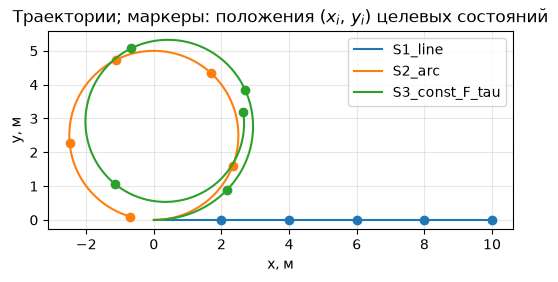

In [7]:
idx = np.searchsorted(T, T_TARGETS)          # индексы целевых моментов на сетке
fig, ax = plt.subplots(figsize=(6, 5))
for n, s in sims.items():
    X = s["X"]
    line, = ax.plot(X[0], X[1], label=n)
    ax.plot(X[0, idx], X[1, idx], "o", color=line.get_color())
ax.set_xlabel("x, м"); ax.set_ylabel("y, м"); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title("Траектории; маркеры: положения $(x_i,\\,y_i)$ целевых состояний")
ax.legend(); plt.show()

**Интерпретация.**

**Результат.** Траектория S1 представляет собой отрезок прямой вдоль оси $x$. Траектория S2 является окружностью радиуса 2,5 м с центром $(0;\,2{,}5)$; её период $2\pi/\omega_0\approx10{,}5$ с, поэтому за 10 с проходится почти вся окружность. Траектория S3 стартует из той же точки с тем же курсом, но скорость $v$ и угловая скорость $\omega$ растут, кривизна $\omega/v$ изменяется (от 0,3 до примерно 0,43 м$^{-1}$), и кривая не является окружностью.

**Значение.** Маркеры соответствуют **положениям $(x_i,y_i)$, связанным с целевыми состояниями** $T_i$ (раздел 10).

**Ограничение.** Рисунок в плоскости $(x,y)$ не показывает остальные компоненты полного целевого состояния ($\theta,\dot x,\dot y,\dot\theta$), поэтому маркеры не визуализируют целевое состояние целиком.

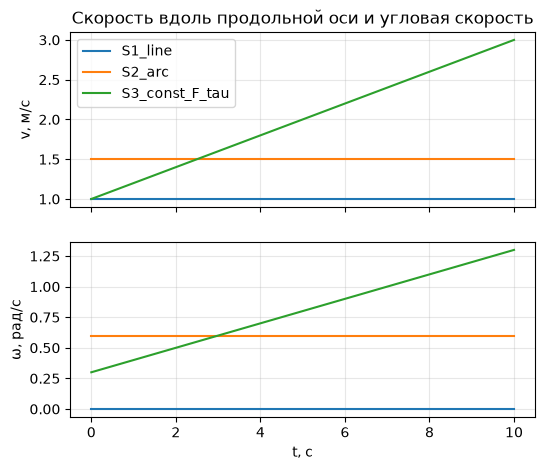

In [8]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(6, 5), sharex=True)
for n, s in sims.items():
    a1.plot(T, body_speed(s["X"]), label=n)
    a2.plot(T, s["X"][5], label=n)
a1.set_ylabel("v, м/с"); a2.set_ylabel("ω, рад/с"); a2.set_xlabel("t, с")
a1.set_title("Скорость вдоль продольной оси и угловая скорость")
for a in (a1, a2):
    a.grid(alpha=0.3)
a1.legend(); plt.show()

**Интерпретация.** В сценариях S1 и S2 скорость $v$ и угловая скорость $\omega$ постоянны. В сценарии S3 обе величины линейно изменяются со временем в соответствии с формулами $v(t)=v_0+Ft/m$ и $\omega(t)=\omega_0+\tau t/J$.

### 9. Анализ неголономной связи

Невязку связи $r$ мы вычисляем функцией `src.metrics.constraint_residual`, а дрейф $|r(t)-r(0)|$ функцией `residual_drift`. Как показано в разделе 4, $r$ является первым интегралом точного потока, поэтому дрейф отражает **ошибку интегрирования**. Допуск «годен/негоден» для него мы не вводим: величину дрейфа мы сообщаем вместе с результатом.

In [9]:
for name, s in sims.items():
    r = constraint_residual(s["X"])
    diag[name]["max |r|"] = np.abs(r).max()
    diag[name]["max |r(t)-r(0)|"] = residual_drift(s["X"]).max()
pd.DataFrame({n: {k: d[k] for k in ("max |r|", "max |r(t)-r(0)|")} for n, d in diag.items()}).T.style.format("{:.2e}")

,max |r|,max |r(t)-r(0)|
S1_line,0.00e+00,0.00e+00
S2_arc,2.89e-10,2.89e-10
S3_const_F_tau,1.59e-09,1.59e-09


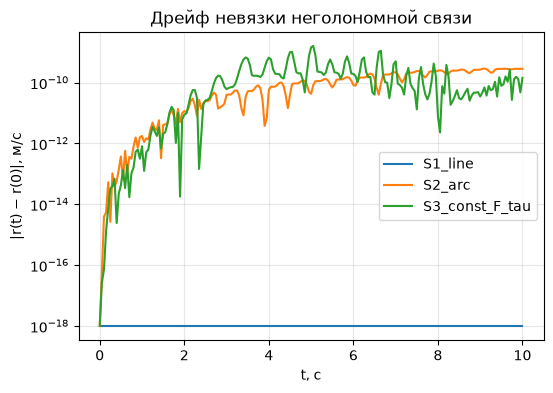

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
for n, s in sims.items():
    ax.semilogy(T, np.maximum(residual_drift(s["X"]), 1e-18), label=n)   # нулевой дрейф S1 рисуется на уровне 1e-18
ax.set_xlabel("t, с"); ax.set_ylabel("|r(t) − r(0)|, м/с")
ax.set_title("Дрейф невязки неголономной связи")
ax.grid(alpha=0.3, which="both"); ax.legend(); plt.show()

**Интерпретация.**

**Результат.** Дрейф для S1 равен нулю. Для S2 и S3 он быстро нарастает в первые секунды и затем колеблется на уровне $10^{-10}$ и $10^{-9}$ м/с, не обязательно монотонно; максимальные значения равны $2{,}9\cdot10^{-10}$ и $1{,}6\cdot10^{-9}$ м/с. Горизонтальная линия на уровне $10^{-18}$ для S1 является техническим отступом на логарифмической шкале.

**Значение.** Так как $r$ является первым интегралом точного потока, дрейф отражает ошибку интегрирования, а не нарушение связи самой моделью. По порядку величины он сопоставим с ошибками из раздела 7 при $\mathrm{rtol}=10^{-10}$.

**Ограничение.** Это измеренная ошибка конкретного расчёта, а не гарантия сохранения связи и не допуск.

**Эксперимент 1: влияние допусков.** Мы интегрируем сценарий S3 строгим (`DOP853`, `rtol=1e-12`) и грубым (`RK45`, `rtol=1e-3`) решателями.

In [11]:
X0_3 = reconstruct(np.array(sims["S3_const_F_tau"]["Z0"]))
ctrl3 = sims["S3_const_F_tau"]["ctrl"]
tight = integrate(rhs, X0_3, T, PARAMS, ctrl3, method="DOP853", rtol=1e-12, atol=1e-14)
loose = integrate(rhs, X0_3, T, PARAMS, ctrl3, method="RK45", rtol=1e-3, atol=1e-6)
print("max дрейф, строгие допуски : %.2e м/с" % residual_drift(tight).max())
print("max дрейф, грубые допуски  : %.2e м/с" % residual_drift(loose).max())

max дрейф, строгие допуски : 1.11e-11 м/с
max дрейф, грубые допуски  : 7.58e-03 м/с


**Интерпретация.** Ослабление допусков увеличивает дрейф невязки примерно на девять порядков (от $\sim10^{-11}$ до $\sim10^{-2}$ м/с). Следовательно, интегратор не сохраняет $r$ точно, и качество выполнения связи зависит от настройки решателя. Поэтому мы сообщаем дрейф вместе с результатом.

**Эксперимент 2: начальное нарушение связи.** Мы берём $X_0$ с $r(X_0)\neq0$. Согласно разделу 4, невязка должна сохраняться (ни затухать, ни нарастать), а редуцированная 5-мерная модель, отбрасывающая боковую скорость, перестаёт описывать ту же систему.

In [12]:
X0_off = np.array([0.0, 0.0, 0.3, 1.0, 0.4, 0.3])
r0 = float(constraint_residual(X0_off))
Xoff = integrate(rhs, X0_off, T, PARAMS, ctrl3, **SOLVER)
Zoff = integrate(rhs_reduced, reduce_state(X0_off), T, PARAMS, ctrl3, **SOLVER)
print("r(X0) = %.4f м/с; max |r(t) - r(0)| = %.2e м/с" % (r0, residual_drift(Xoff).max()))
print("max расстояние между 6- и 5-мерной моделью: %.3f м" % position_error(Xoff, Zoff).max())

r(X0) = -0.0866 м/с; max |r(t) - r(0)| = 1.99e-09 м/с
max расстояние между 6- и 5-мерной моделью: 0.764 м


**Интерпретация.** Нарушение связи $r(X_0)\approx-0{,}087$ м/с сохраняется практически постоянным: его изменение имеет порядок $2\cdot10^{-9}$ м/с, то есть порядок ошибки интегрирования. Модель не «исправляет» недопустимое начальное условие. При $r\neq0$ 5-мерная модель даёт иную траекторию (расхождение в положении до $\approx0{,}76$ м за 10 с), поэтому её эквивалентность полной модели ограничена множеством $r=0$.

### 10. Формирование целевых состояний

Целевые состояния $T_i=X(t_i)$ мы берём из плотной траектории функцией `src.dataset.sample_targets` (моменты $t_i$ должны быть узлами сетки). Для каждого состояния мы также записываем невязку $r$ и управления $F,\tau$ в момент $t_i$. Набор экспортируется функцией `save_targets` (CSV и метаданные JSON) и загружается обратно функцией `load_targets`, которая проверяет схему, конечность значений, монотонность времени и согласованность записанной невязки с состоянием.

In [13]:
target_sets = [sample_targets(n, T, s["X"], T_TARGETS, s["ctrl"], {"F": s["F"], "tau": s["tau"]}) for n, s in sims.items()]
rows = [[ts.trajectory_id, ts.t[i], *ts.X[:, i], float(constraint_residual(ts.X[:, i])), *ts.inputs[:, i]]
        for ts in target_sets for i in range(ts.t.size)]
cols = ["id", "t, с", "x, м", "y, м", "θ, рад", "vx, м/с", "vy, м/с", "ω, рад/с", "r, м/с", "F, Н", "τ, Н·м"]
targets_df = pd.DataFrame(rows, columns=cols)
print("Всего целевых состояний:", len(targets_df))
targets_df.style.format({c: "{:.6f}" for c in cols[1:8]} | {"r, м/с": "{:.1e}", "F, Н": "{:.1f}", "τ, Н·м": "{:.1f}"}).hide(axis="index")

Всего целевых состояний: 15


id,"t, с","x, м","y, м","θ, рад","vx, м/с","vy, м/с","ω, рад/с","r, м/с","F, Н","τ, Н·м"
S1_line,2.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.0e+00,0.0,0.0
S1_line,4.000000,4.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.0e+00,0.0,0.0
S1_line,6.000000,6.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.0e+00,0.0,0.0
S1_line,8.000000,8.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.0e+00,0.0,0.0
S1_line,10.000000,10.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.0e+00,0.0,0.0
S2_arc,2.000000,2.330098,1.594106,1.200000,0.543537,1.398059,0.600000,1.2e-11,0.0,0.0
S2_arc,4.000000,1.688658,4.343484,2.400000,-1.106091,1.013195,0.600000,5.8e-11,0.0,0.0
S2_arc,6.000000,-1.106301,4.741896,3.600000,-1.345138,-0.663781,0.600000,8.3e-11,0.0,0.0
S2_arc,8.000000,-2.490412,2.281253,4.800000,0.131248,-1.494247,0.600000,2.4e-10,0.0,0.0
S2_arc,10.000000,-0.698539,0.099574,6.000000,1.440255,-0.419123,0.600000,2.8e-10,0.0,0.0


**Интерпретация.** Мы получили 15 целевых состояний (3 сценария по 5 моментов времени). Для S1 и S2 значения совпадают с замкнутой формой, для S3 они совпадают с независимо проверенным решением из раздела 8. Невязка $r$ в целевых состояниях мала. Целевые состояния являются **синтетическим** результатом моделирования предварительной модели.

In [14]:
with tempfile.TemporaryDirectory() as d:
    out = save_targets(target_sets, pathlib.Path(d) / "targets", {"purpose": "проверка записи и чтения"})
    back = load_targets(out)
    print("файлы:", sorted(p.name for p in out.iterdir()))
    ok = all(np.array_equal(a.X, b.X) and np.array_equal(a.t, b.t) and np.array_equal(a.inputs, b.inputs)
             for a, b in zip(target_sets, back))
print("Запись и чтение без потерь (побитовое совпадение):", ok)

# Согласованность с экспериментальным скриптом experiments/run_kt3.py
same = all(np.array_equal(run_scenario(n, *rest)["set"].X, ts.X) for (n, *rest), ts in zip(SCENARIOS, target_sets))
print("Целевые состояния совпадают с результатом run_kt3.run_scenario:", same)

файлы: ['metadata.json', 'targets.csv']
Запись и чтение без потерь (побитовое совпадение): True
Целевые состояния совпадают с результатом run_kt3.run_scenario: True


**Интерпретация.** Цикл «запись, чтение» воспроизводит данные побитово. Цепочка в ноутбуке даёт те же состояния, что и экспериментальный скрипт `experiments/run_kt3.py`, из которого получен набор данных в каталоге `results/`.

### 11. Анализ результатов

Мы сводим независимые проверки в одну таблицу. Для перекрёстной проверки каждый сценарий дополнительно интегрируется в редуцированной 5-мерной форме. Для проверки динамики мы используем энергетический баланс $E(t)-E(0)-\int_0^t P\,ds$. Интеграл вычисляется по формуле Симпсона на сетке с шагом 0,05 с, поэтому значение баланса включает как ошибку интегрирования ОДУ, так и ошибку квадратуры.

In [15]:
for name, s in sims.items():
    Z = integrate(rhs_reduced, reduce_state(reconstruct(np.array(s["Z0"]))), T, PARAMS, s["ctrl"], **SOLVER)
    diag[name]["|X - R(Z)| (5-мерная модель)"] = np.abs(reconstruct(Z) - s["X"]).max()
    diag[name]["ошибка баланса энергии, Дж"] = np.abs(energy_balance_error(T, s["X"], PARAMS, s["ctrl"])).max()
summary = pd.DataFrame(diag).T
summary = summary[["max |r|", "max |r(t)-r(0)|", "|X - R(Z)| (5-мерная модель)", "ошибка баланса энергии, Дж",
                   "ошибка к замкнутой форме", "ошибка v(t)", "ошибка omega(t)", "ошибка theta(t)", "ошибка (x,y) к квадратуре"]]
summary.style.format("{:.2e}", na_rep="нет")

,max |r|,max |r(t)-r(0)|,|X - R(Z)| (5-мерная модель),"ошибка баланса энергии, Дж",ошибка к замкнутой форме,ошибка v(t),ошибка omega(t),ошибка theta(t),"ошибка (x,y) к квадратуре"
S1_line,0.00e+00,0.00e+00,1.78e-15,0.00e+00,6.22e-15,нет,нет,нет,нет
S2_arc,2.89e-10,2.89e-10,1.84e-09,1.01e-08,1.87e-09,нет,нет,нет,нет
S3_const_F_tau,1.59e-09,1.59e-09,5.79e-09,3.54e-08,нет,1.59e-09,5.55e-16,3.55e-15,2.93e-09


**Интерпретация.**

**Результат.** Наибольшие наблюдаемые расхождения таковы: с замкнутой формой $6\cdot10^{-15}$ (S1) и $1{,}9\cdot10^{-9}$ (S2); с 5-мерной формой не более $5{,}8\cdot10^{-9}$; невязка и её дрейф не более $1{,}6\cdot10^{-9}$ м/с. Абсолютная ошибка энергетического баланса равна $1{,}0\cdot10^{-8}$ Дж (S2) и $3{,}5\cdot10^{-8}$ Дж (S3), для S1 она равна нулю.

**Значение.** Величины порядка $10^{-9}$ согласуются с уровнем ошибки интегрирования ОДУ при $\mathrm{rtol}=10^{-10}$ (раздел 7). В энергетическом балансе мы различаем ошибку интегрирования ОДУ, ошибку квадратуры и суммарную наблюдаемую ошибку. В сценарии S2 мощность $P$ равна нулю, квадратура вклада не даёт, и значение отражает только ошибку интегрирования $E(t)$. В сценарии S3 приведена суммарная наблюдаемая ошибка: вклады интегрирования ОДУ и квадратуры на сетке 0,05 с мы по отдельности не оценивали.

**Ограничение.** Расхождений, указывающих на ошибку вывода или реализации, мы не обнаружили. Это означает согласие реализации с принятыми уравнениями, но не адекватность самих уравнений.

**Что подтверждено и в каком смысле.**

* Уравнения модели согласуются с независимым символьным выводом (раздел 6) и с замкнутыми решениями сценариев S1 и S2.
* Решение сценария S3 согласуется с аналитическими $v,\omega,\theta$ и с квадратурой для $x,y$.
* Полная и редуцированная формы дают один результат на множестве $r=0$.
* Невязка связи и её дрейф измерены. Дрейф мы интерпретируем как ошибку интегрирования, но допуск для него не вводим.

Все проверки подтверждают **корректность реализации принятых уравнений**. Они не доказывают, что Baseline v1 адекватно описывает физический колёсный робот.

### 12. Ограничения модели

Мы выделяем следующие ограничения.

1. **Предварительный статус.** Baseline v1 является нашим первым приближением. Модель не описывает конкретный колёсный привод и схему Аккермана.
2. **Упрощающие допущения.** Мы рассматриваем плоское абсолютно твёрдое тело с опорной точкой в центре масс и идеальной связью без бокового скольжения. Динамика приводов и рулевого механизма, а также диссипация (трение) не учитываются.
3. **Синтетические данные.** Параметры $m$ и $J$, управления, начальные условия и моменты $t_i$ являются допущениями эксперимента, а не измерениями. Целевые состояния представляют собой результат моделирования.
4. **Разомкнутое управление.** Функции $F(t)$ и $\tau(t)$ заданы заранее, замкнутого контура и стабилизации нет. Множество $r=0$ не является притягивающим: нарушение связи не затухает.
5. **Численное решение.** Дрейф невязки есть ошибка интегрирования. Допуск, который можно было бы считать критерием годности, мы не обосновали и потому не вводим.
6. **Пороги проверок.** Числовые пороги в `tests/` являются техническими порогами проверки программы, выбранными с запасом над наблюдаемыми ошибками. Это не физические допуски.
7. **Масштаб проверки.** Мы рассмотрели три простых сценария с постоянными управлениями и одним набором параметров. Устойчивость результатов к другим параметрам и управлениям мы не исследовали.
8. **Редуцированная модель.** Она служит только для проверки и эквивалентна полной модели лишь при $r=0$.
9. **Границы текущей версии.** Baseline v1 пока не содержит переменной направления $\phi$, стабилизации типа Еругина (Erugin) и нейросетевого управления. Эти расширения не приняты и не реализованы.
10. **Дальнейшее использование данных.** Сформированные здесь 15 синтетических состояний могут быть использованы как целевые состояния в последующих экспериментах по управлению при условии дальнейшей проверки модели научным руководителем.
11. **Перспективы.** В дальнейшей работе возможно исследование методов обратной задачи динамики и нейронных дифференциальных уравнений для построения управляющих воздействий [5]. Это расширение не входит в Baseline v1.

### 13. Вывод

В работе мы построили и проверили воспроизводимую цепочку «уравнения, численная траектория, целевые состояния» для предварительной модели Baseline v1 плоского тела с неголономной связью.

Из уравнений Лагранжа-Даламбера мы получили множитель $\lambda=-m\,v\,\omega$ и векторное поле шестимерной модели. Мы показали, что невязка связи $r$ является первым интегралом, а также что выполняются соотношения $\dot v=F/m-\omega r$ и $\dot E=P-m\,v\,\omega\,r$. Эти соотношения подтверждены символьно (SymPy) независимо от кода и численно на реализованном поле.

Численное интегрирование (`DOP853`, `rtol=1e-10`, `atol=1e-12`) трёх сценариев согласуется с независимыми эталонами: с замкнутыми решениями для S1 и S2, а для S3 с аналитическими $v(t),\omega(t),\theta(t)$ и квадратурой для $x(t),y(t)$. Дрейф невязки связи мал и отражает ошибку интегрирования; при грубых допусках он заметно возрастает. Редуцированная 5-мерная форма совпадает с полной при $r=0$ и отличается от неё при $r\neq0$.

Мы сформировали набор из 15 синтетических целевых состояний $T_i=X(t_i)$ с невязкой и управлениями; их запись и чтение выполняются без потерь.

Полученные результаты подтверждают корректность реализации принятых уравнений, но не адекватность модели физическому роботу. Модель, параметры и моменты $t_i$ остаются предварительными допущениями.

## Литература

1. Bloch A. M. Nonholonomic Mechanics and Control. 2nd ed. New York: Springer, 2015. DOI: 10.1007/978-1-4939-3017-3.
2. Murray R. M., Li Z., Sastry S. S. A Mathematical Introduction to Robotic Manipulation. Boca Raton: CRC Press, 1994.
3. Hairer E., Nørsett S. P., Wanner G. Solving Ordinary Differential Equations I: Nonstiff Problems. 2nd rev. ed. Berlin, Heidelberg: Springer, 1993. DOI: 10.1007/978-3-540-78862-1.
4. Dormand J. R., Prince P. J. A Family of Embedded Runge-Kutta Formulae // Journal of Computational and Applied Mathematics. 1980. Vol. 6, No. 1. P. 19-26. DOI: 10.1016/0771-050X(80)90013-3.
5. Шорохов С. Г. Управление динамической системой с линейными гироскопическими силами при помощи нейронных дифференциальных уравнений // Динамические системы и компьютерные науки: теория и приложения (DYSC 2026): материалы 8-й Международной конференции. 2026. С. 1-4.